<a href="https://colab.research.google.com/github/XanderPatterson/4487-IS-Class-Labs/blob/main/assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('hotels (1).csv')

display(df.head())

display(df.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. I was looking and the columns of company and the agent have many missing values because not everyone uses agengies or booking agencies to find hotels. There also looks like a few errors when you look at things like average price because even on one there looks to be a negative number. There are also rooms that show a zero price which could mean an employee stay or even some type of promotion.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
from sklearn.preprocessing import StandardScaler

features = ['lead_time', 'stays_in_week_nights', 'stays_in_weekend_nights', 'total_of_special_requests', 'adr']

df_clean = df.drop_duplicates().copy()
df_clean = df_clean[(df_clean['adr'] >= 0) & (df_clean['lead_time'] <= 500)]

df_clean = df_clean.dropna(subset=features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[features])

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
display(X_scaled_df.head())

,lead_time,stays_in_week_nights,stays_in_weekend_nights,total_of_special_requests,adr
0,3.648151,-1.296249,-1.031575,-0.801913,-1.637347
1,-0.760131,-0.884301,-1.031575,-0.801913,-0.286547
2,-0.681176,-0.884301,-1.031575,-0.801913,-0.286547
3,-0.668017,-0.472352,-1.031575,0.364794,0.127699
4,-0.852244,-0.472352,-1.031575,-0.801913,0.289795


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I looked into stays in week nights, staying in weekend nights, total of special requestions, adr or the averages, and then lead time because these were the best to capture customer booking behavior, legnths of trips, and what customers are looking for.

2. I am looking to find the different typs of spending groups. The shorter stays could be someone on business trips, family trips for the weekedns and longer stays. and then even looking at the budget and luxury spenders in groups.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

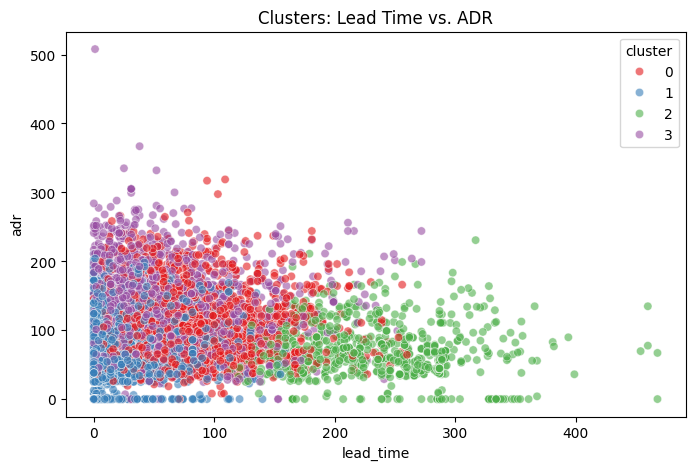

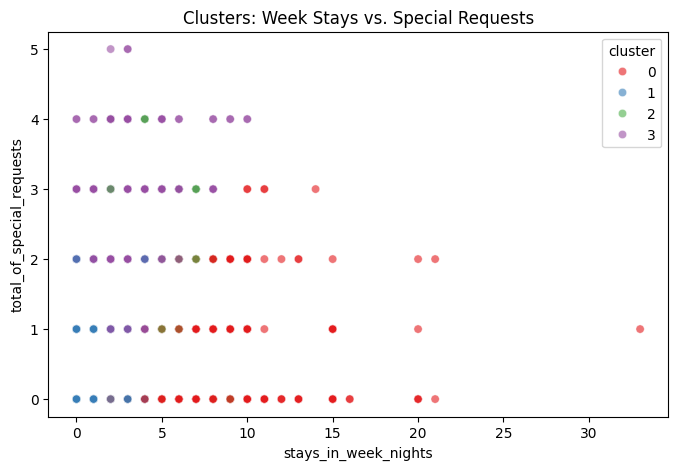

,lead_time,stays_in_week_nights,stays_in_weekend_nights,total_of_special_requests,adr
cluster,,,,,
0,79.176130,5.822818,2.398002,0.451104,107.898985
1,19.015849,1.500897,0.456041,0.328648,64.599844
2,232.600737,3.964373,1.491400,0.412776,69.846622
3,58.139772,2.995201,1.071386,1.810438,134.588680


In [3]:
from sklearn.cluster import KMeans

k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled_df)

df_clean['cluster'] = clusters

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='lead_time', y='adr', hue='cluster', palette='Set1', alpha=0.6)
plt.title('Clusters: Lead Time vs. ADR')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='stays_in_week_nights', y='total_of_special_requests', hue='cluster', palette='Set1', alpha=0.6)
plt.title('Clusters: Week Stays vs. Special Requests')
plt.show()

cluster_summary = df_clean.groupby('cluster')[features].mean()
display(cluster_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose the k value of 4 because it shows a value of splitting the guests into meaning ful categories. Ones like budget, business, family, and just standard stays. This makes it not too specific and wouldn't overlap other categories either.

2. First Cluster, Budget would be shown by lower adr and shorter lead tiems. These are weekend getaway travelers or just random travelers.
Second, Long Term and Planners. This is a higher lead time. These are the guests who book bonths in advance and planned for vactions or holidays.
Third, Higher spenders and special requests, these are the ones that stand out with a high adr and higher total special requests. They spend more on getting the premium services.
Last, The Extended Weekday stays. This has the higher numbers in the week night stays column. This is for the travels that stay durning the workweek


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

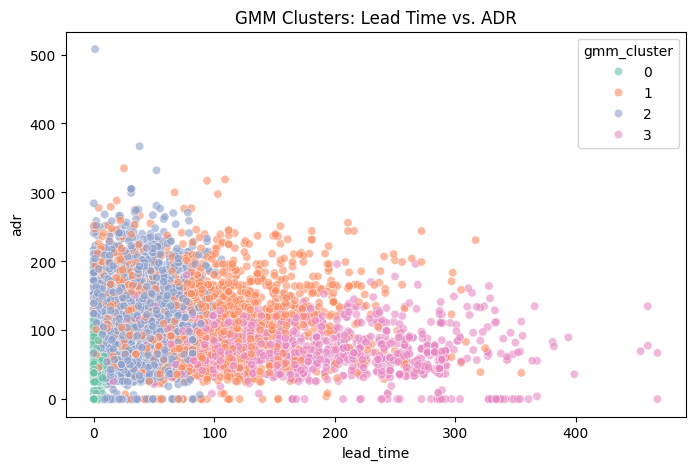

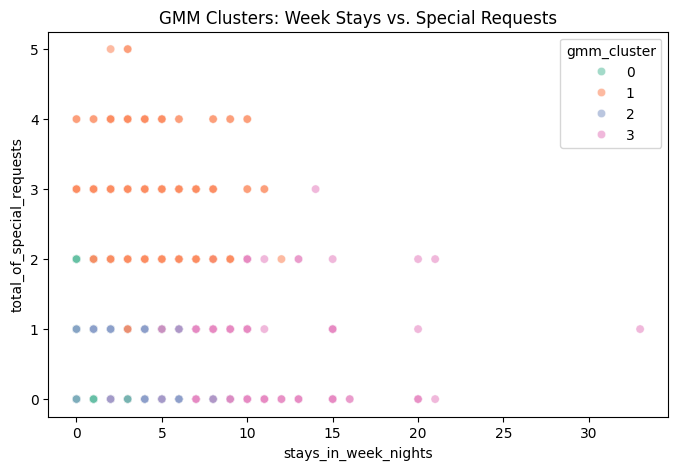

,lead_time,stays_in_week_nights,stays_in_weekend_nights,total_of_special_requests,adr
gmm_cluster,,,,,
0,1.812183,1.032360,0.273477,0.402284,47.755273
1,89.575851,3.600619,1.326625,1.726522,116.649876
2,32.955026,2.971721,1.144123,0.345486,105.772177
3,177.825509,5.467136,2.133020,0.248044,70.961753


In [4]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=k, random_state=42)
gmm_clusters = gmm.fit_predict(X_scaled_df)

df_clean['gmm_cluster'] = gmm_clusters

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='lead_time', y='adr', hue='gmm_cluster', palette='Set2', alpha=0.6)
plt.title('GMM Clusters: Lead Time vs. ADR')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='stays_in_week_nights', y='total_of_special_requests', hue='gmm_cluster', palette='Set2', alpha=0.6)
plt.title('GMM Clusters: Week Stays vs. Special Requests')
plt.show()

gmm_cluster_summary = df_clean.groupby('gmm_cluster')[features].mean()
display(gmm_cluster_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM had a similiar look with the K means, but because of the way that this clusters, it helps it look better for things like the overlapping that could happen in the K means and rather than have the lines around the data points.

2. GMM could help answer questions about the customer overlap to help find the guest who share traits of both business travelers and just people on vacation. This is useful for targeting marketing where a customer might qualify for a certain promotion.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

sample_df = X_scaled_df.sample(n=min(10000, len(X_scaled_df)), random_state=42)

kmeans_sample_labels = kmeans.predict(sample_df)
kmeans_wcss = kmeans.inertia_
kmeans_sil = silhouette_score(sample_df, kmeans_sample_labels)
kmeans_db = davies_bouldin_score(sample_df, kmeans_sample_labels)

gmm_sample_labels = gmm.predict(sample_df)

gmm_sil = silhouette_score(sample_df, gmm_sample_labels)
gmm_db = davies_bouldin_score(sample_df, gmm_sample_labels)

metrics_table = pd.DataFrame({
    'Metric': ['Silhouette Score (Higher is better)', 'Davies-Bouldin Index (Lower is better)'],
    'KMeans': [kmeans_sil, kmeans_db],
    'GMM': [gmm_sil, gmm_db]})
display(metrics_table)

,Metric,KMeans,GMM
0,Silhouette Score (Higher is better),0.288399,0.122100
1,Davies-Bouldin Index (Lower is better),1.374282,1.743782


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans score and because it forces the data points into boundaries, whereas GMM allows for soft probabilistic overlap.

5.3. I would recommend KMeans for the marketing segmentation because it is simple to explain, fast to compute, and creates groups. GMM is better if the analyst needs to understand customer overlap or uncertainty in the data.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
sorted_cluster_summary = cluster_summary.sort_values(by='adr', ascending=False)
display(sorted_cluster_summary)

,lead_time,stays_in_week_nights,stays_in_weekend_nights,total_of_special_requests,adr
cluster,,,,,
3,58.139772,2.995201,1.071386,1.810438,134.588680
0,79.176130,5.822818,2.398002,0.451104,107.898985
2,232.600737,3.964373,1.491400,0.412776,69.846622
1,19.015849,1.500897,0.456041,0.328648,64.599844


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. High Spenders and people focused on detail: Guests with high adr and many special requests.
Standard and the family vacationers: Moderate lead times with a mix of week and weekend nights.
Business Travelers: Weekday stays with shorter lead times.
Bargain and budget travelers: Low adr and short-term bookings.

2. For highspenders, offer upsells like spa packages or room upgrades. For its business travelers, offer loyalty perks and fast check in. For budget travelers, provide last-minute weekend discounts or promotional room rates.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Unlike supervised learning where you have a clear target (like "canceled" or "not canceled"), unsupervised learning requires you to interpret the results yourself and decide what makes a good cluster to accuratly describe the data.

2. You use clustering when you don't have historical labels or predefined categories, but you want to discover natural groupings or hidden segments within your data like customer behavior.

3. Clustering helps us automatically sort our customers into natural groups based on their behavior, allowing us to see who our main types of guests are so we can target them with better promotions and services. This helps when there is a lot of data and we just need help describing it.

4. It connects by applying data mining and machine learning techniques to solve a real-world business problem and turn raw data into strategic decision-making tools. This help takes a lot of raw data and using it to find the best outcome and sort the data better. It helps if there is a lot of data and you just need help splitting it up better.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [7]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 898500 bytes to assignment_09_clustering.html
